# New regressors for the linear model: recurrence, solar cycle, protons (none kept)

**The question:** do regressors the model has never seen improve the submitted linear model
on the official metric? From `docs/model_review.md`, item 4, and the 2026-10-28 plan:
- **recurrence:** Bt and log temperature one solar rotation earlier, the 72 h starting
  26, 27 or 28 days before t0 (the speed terms already use 27 and 13.5 days);
- **solar cycle:** the 81-day F10.7 mean and its trend (the 81- or 27-day mean minus the
  same mean 27 days earlier, per day);
- **protons:** GOES >= 10 MeV flux, log10 floored at 1 pfu: the 6-hour mean and the 24- and
  72-hour maxima.

**The run** (`python -m training.new_features`): each candidate added on its own to the
submitted config (four regressors, official loss weights, blend 0.25), refitted on every
yearly fold; then the best candidate of each group together. Missing values of a new
candidate get the fold's fit median, so every variant fits on the same runs. Score: official
S_final against the official truth, relative to persistence, geometric mean over folds.

**Decision rule** (set before running): keep a candidate only if it is more than 1% better
than the submitted config and wins at least 4 of 6 folds. The eval year is not used.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import new_features as nf
from training import pull_protons

df = pd.read_csv(nf.EXPERIMENTS / "new_features.csv").set_index("variant")
years = [c.split()[1] for c in df.columns if c.startswith("ratio ")]
ratios = df[[f"ratio {y}" for y in years]].astype(float)
rel = ratios / ratios.loc["shipped"]
rel.columns = years
groups = {n: g for g, names in nf.group_specs().items() for n in names}
summary = pd.DataFrame({
    "group": [groups.get(v.removeprefix("+ "), "combination") if v != "shipped" else "-"
              for v in df.index],
    "S_final km/s": df[[f"S {y}" for y in years]].mean(axis=1),
    "vs shipped %": 100 * (np.exp(np.log(rel).mean(axis=1)) - 1),
    "folds won": (rel < 1).sum(axis=1),
}, index=df.index).sort_values("vs shipped %")
summary["keep"] = (summary["vs shipped %"] < -1) & (summary["folds won"] >= 4)
with pd.option_context("display.float_format", "{:.3f}".format):
    display(summary)

,group,S_final km/s,vs shipped %,folds won,keep
variant,,,,,
shipped + log_temperature_lag27_72h + f107_trend_648h + log_p10_mean_6h,combination,88.129,-0.430,4,False
+ log_p10_mean_6h,protons,88.226,-0.300,2,False
+ log_p10_max_24h,protons,88.388,-0.098,3,False
+ log_temperature_lag27_72h,recurrence,88.465,-0.065,3,False
shipped,-,88.486,0.000,0,False
+ f107_trend_648h,cycle,88.521,0.076,2,False
+ log_temperature_lag28_72h,recurrence,88.531,0.079,3,False
+ log_p10_max_72h,protons,88.615,0.107,3,False
+ f107_mean_1944h,cycle,88.644,0.135,3,False


## 1. Every candidate against the submitted config

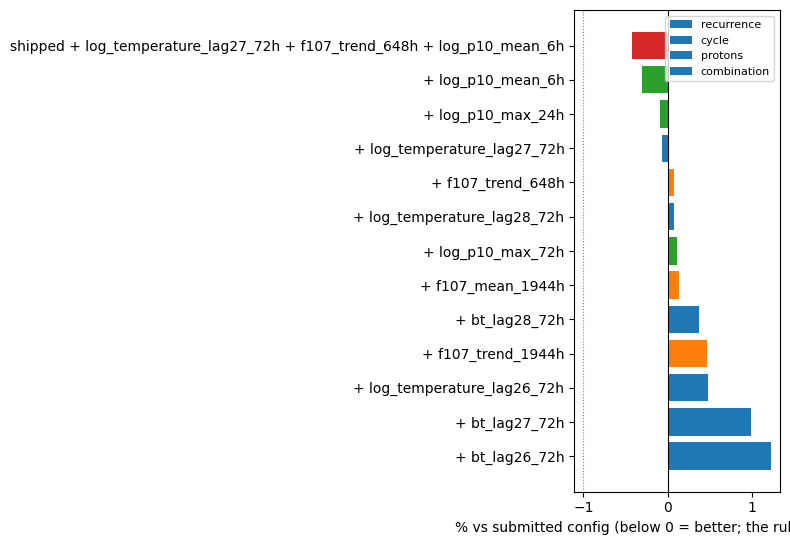

In [2]:
s = summary.drop("shipped")
colors = {"recurrence": "C0", "cycle": "C1", "protons": "C2", "combination": "C3"}
fig, ax = plt.subplots(figsize=(8, 0.35 * len(s) + 1))
ax.barh(s.index, s["vs shipped %"], color=[colors[g] for g in s["group"]])
ax.axvline(0, color="k", lw=.8)
ax.axvline(-1, color="grey", ls=":", lw=.8)
ax.invert_yaxis()
ax.set_xlabel("% vs submitted config (below 0 = better; the rule needs < -1%)")
for g, c in colors.items():
    ax.barh([], [], color=c, label=g)
ax.legend(fontsize=8)
plt.tight_layout()

## 2. By fold

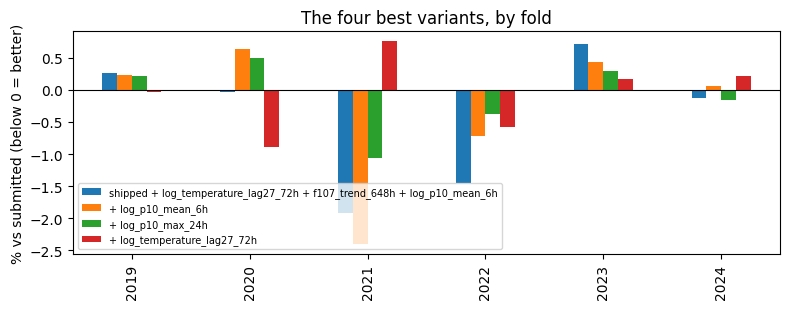

In [3]:
best = summary.drop("shipped").index[:4]
ax = (100 * (rel.loc[best].T - 1)).plot.bar(figsize=(8, 3.2))
ax.axhline(0, color="k", lw=.8)
ax.set_ylabel("% vs submitted (below 0 = better)")
ax.set_title("The four best variants, by fold")
ax.legend(fontsize=7)
plt.tight_layout()

## 3. The proton history

OMNI's GOES-13/15 >10 MeV flux to 2020-03-04, then NCEI GOES-R SGPS (GOES-16, GOES-18 from
2025-04-07), summed over the differential channels above 10 MeV (`training.pull_protons`).
March to October 2020 is missing (solar minimum). The quiet-time level differs by source, so
the features count only flux above 1 pfu.

hours >= 10 pfu per year:
time
2016-01-01 00:00:00+00:00      0
2017-01-01 00:00:00+00:00    191
2018-01-01 00:00:00+00:00      0
2019-01-01 00:00:00+00:00      0
2020-01-01 00:00:00+00:00      0
2021-01-01 00:00:00+00:00     34
2022-01-01 00:00:00+00:00     18
2023-01-01 00:00:00+00:00    296
2024-01-01 00:00:00+00:00    659
2025-01-01 00:00:00+00:00    156
2026-01-01 00:00:00+00:00     70
Freq: YS-JAN


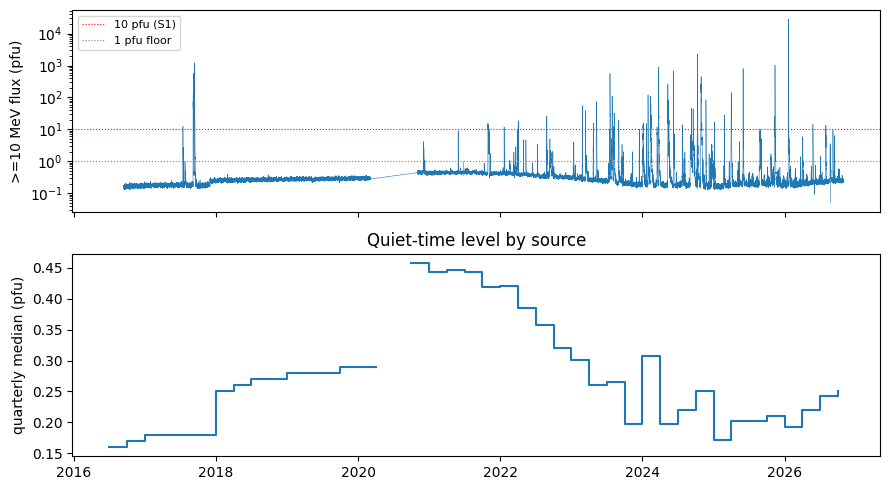

In [4]:
flux = pull_protons.load()
quiet = flux.resample("QS").median()
events = (flux >= 10).resample("YS").sum()
fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
axes[0].semilogy(flux.index, flux.clip(lower=0.05), lw=.4)
axes[0].axhline(10, color="r", ls=":", lw=.8, label="10 pfu (S1)")
axes[0].axhline(1, color="grey", ls=":", lw=.8, label="1 pfu floor")
axes[0].set_ylabel(">=10 MeV flux (pfu)")
axes[0].legend(fontsize=8)
axes[1].step(quiet.index, quiet, where="post")
axes[1].set_ylabel("quarterly median (pfu)")
axes[1].set_title("Quiet-time level by source")
plt.tight_layout()
print("hours >= 10 pfu per year:")
print(events[events.index >= "2016"].astype(int).to_string())

In [5]:
from training import linear_model as tl
from training.datasets import load_train

t0s = tl.training_runs(load_train())
table = nf.new_table(t0s)
p = table[[c for c in table if c.startswith("log_p10")]]
print("share of training runs with any flux >= 1 pfu in the window:")
print((p > 0).mean().round(4).to_string())
print("missing:", p.isna().mean().round(3).to_dict())

share of training runs with any flux >= 1 pfu in the window:
log_p10_mean_6h    0.0614
log_p10_max_24h    0.0786
log_p10_max_72h    0.1160
missing: {'log_p10_mean_6h': 0.076, 'log_p10_max_24h': 0.075, 'log_p10_max_72h': 0.075}


## Findings

**None of the 12 candidates passes the rule (more than 1% better, at least 4 of 6 folds). Nothing is built; the submitted config stays.**

- **Recurrence:** Bt one rotation earlier is worse at every lag (up to +1.2%); temperature at 27 days ties (−0.06%, 3 of 6). The speed terms already carry the 27-day signal.
- **Solar cycle:** the 81-day level and both trends are within ±0.5%; the 81-day trend loses most in 2023-2024, at the cycle's maximum.
- **Protons:** the 6-hour mean is the best single candidate (−0.30%) but wins only 2 of 6 folds; its gain is the 2021 fold (−2.4%). Events are rare (no hour ≥ 10 pfu in 2018-2020), so the column is 0 in most runs.
- **Best of each group together:** −0.43%, 4 of 6 folds, with its members picked on the same folds; under half the bar.

Details: `docs/new_features.md`.
